# Spectrogram and spectrum

For the real capture and for each anomaly type: the spectrogram on top and the spectrum
(average power vs frequency) underneath, on the same frequency axis.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

from spectrogram import iq_to_spectrogram
from anomalies import add_tone, add_chirp, add_pulse, add_comb, add_ofdm, add_fsk

## Capture

In [2]:
name = "IQ_2024-04-19T17-22-10_111471224"
path = "data/iq/" + name
fs = json.load(open(path + ".json"))["sampling_frequency"]  # 61.44 MHz

raw = np.fromfile(path + ".bin", dtype=np.int32)
iq = raw[0::2] + 1j * raw[1::2]

clean_db, duration_ms = iq_to_spectrogram(iq, fs)

## Plotting helper

The spectrum is the mean of the spectrogram rows inside a time window. The mean is taken on
linear power and only then converted to dB.

In [3]:
def spectrum_db(sxx_db, rows):
    """Average power of the selected time rows, per frequency column, in dB."""
    # Averaging dB values would be a geometric mean, which plays down short strong bursts
    return 10 * np.log10(np.mean(10 ** (sxx_db[rows] / 10), axis=0))


def show(sxx_db, title, start=0, stop=None, reference=None):
    """Spectrogram (top) and its spectrum over start..stop [s] (bottom), same frequency axis.

    reference: clean spectrogram, averaged over the same rows and drawn in grey.
    """
    n_rows, n_cols = sxx_db.shape
    # Centre of each row / column, as imshow draws them with this extent
    t_ms = (np.arange(n_rows) + 0.5) * duration_ms / n_rows
    f_mhz = (np.arange(n_cols) + 0.5) * 48 / n_cols - 24
    stop_ms = duration_ms if stop is None else stop * 1e3
    rows = (t_ms >= start * 1e3) & (t_ms <= stop_ms)

    # constrained layout keeps both panels the same width, so the frequency axes line up
    # even though only the spectrogram has a colorbar
    fig, (ax_img, ax_spec) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                                          height_ratios=[3, 1.3], layout="constrained")
    im = ax_img.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
                       vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
    fig.colorbar(im, ax=ax_img, label="Power [dB]")
    if rows.sum() < n_rows:  # mark the rows that the spectrum averages
        for t in (start * 1e3, stop_ms):
            ax_img.axhline(t, color="cyan", linestyle="--", linewidth=1)
    ax_img.set_ylabel("Time [ms]")
    ax_img.set_title(title)

    ax_spec.plot(f_mhz, spectrum_db(sxx_db, rows), color="C0", linewidth=1,
                 label="with anomaly")
    if reference is not None:
        # Grey on top (a bit thicker, to cover the blue line where the two are equal): the
        # blue line then shows only where the anomaly changes the spectrum
        ax_spec.plot(f_mhz, spectrum_db(reference, rows), color="grey", linewidth=1.3,
                     label="clean capture")
        # Legend above the plot, so it never hides a peak
        ax_spec.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=2, fontsize="small",
                       frameon=False)
    ax_spec.set_xlim(-24, 24)
    ax_spec.set_xlabel("Frequency [MHz]")
    ax_spec.set_ylabel("Power [dB]")
    ax_spec.set_title(f"mean over {start * 1e3:.1f}-{stop_ms:.1f} ms", loc="left",
                      fontsize="small")
    ax_spec.grid(alpha=0.3)
    plt.show()

## Clean capture

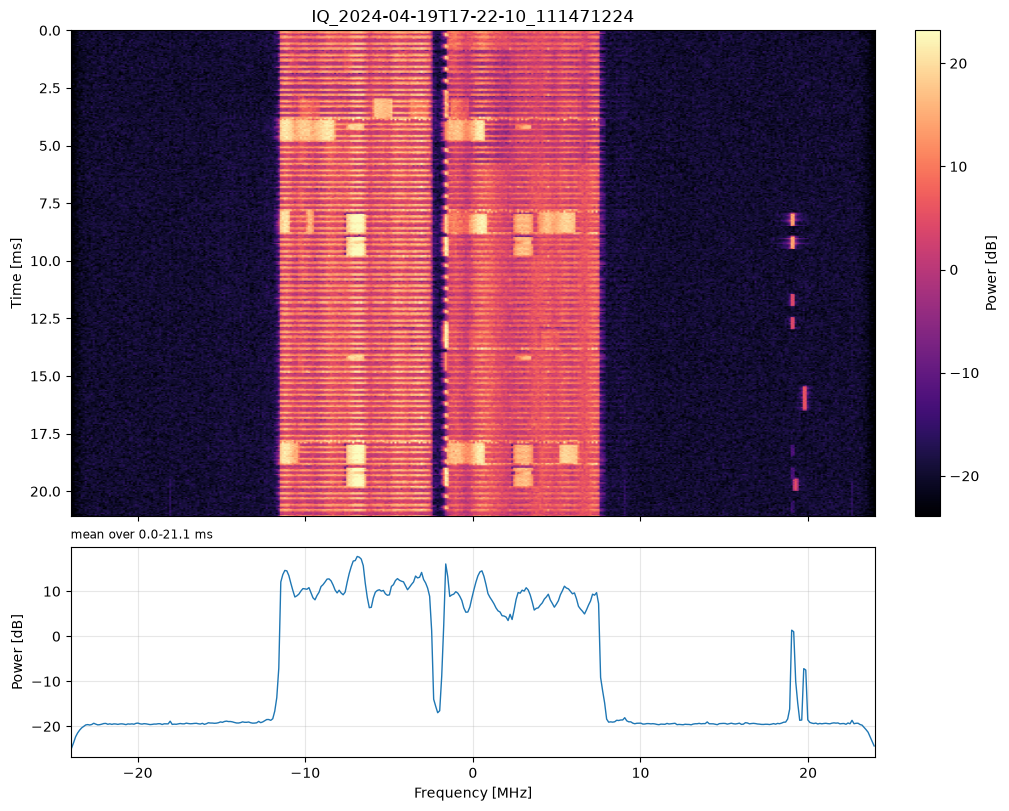

In [4]:
show(clean_db, name)

## Anomalies

Same parameters as in `try_data.ipynb`. The spectrum averages only the rows inside the
anomaly's time window (dashed lines); the grey line is the clean capture over the same rows.

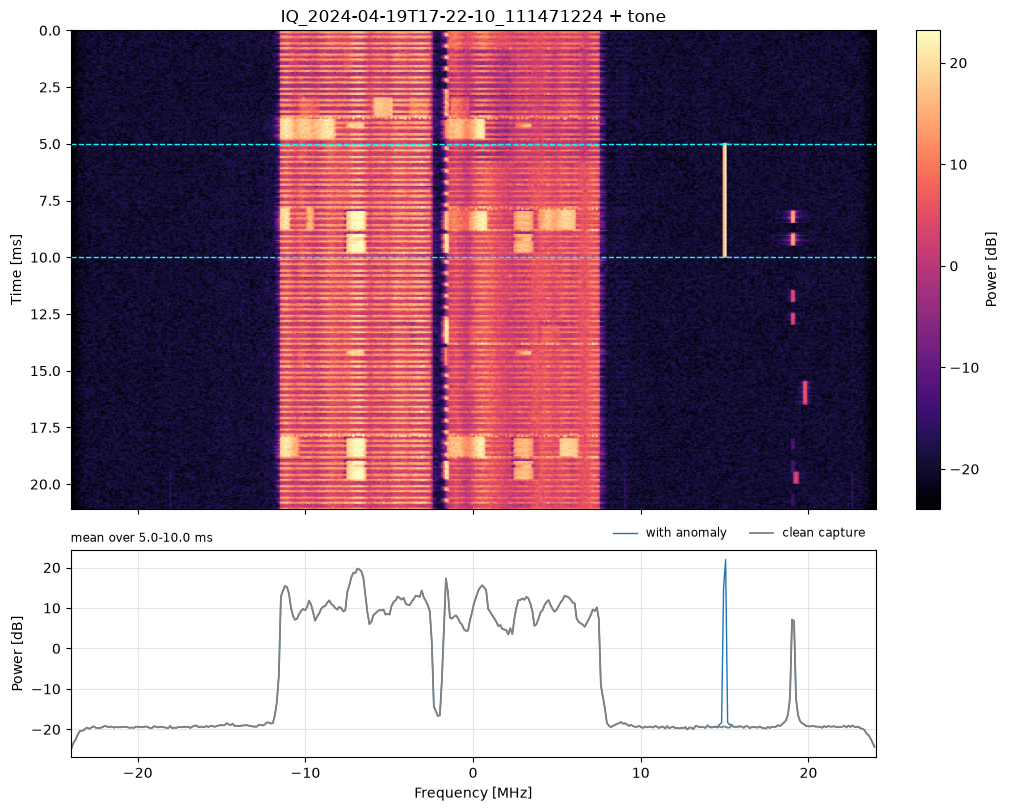

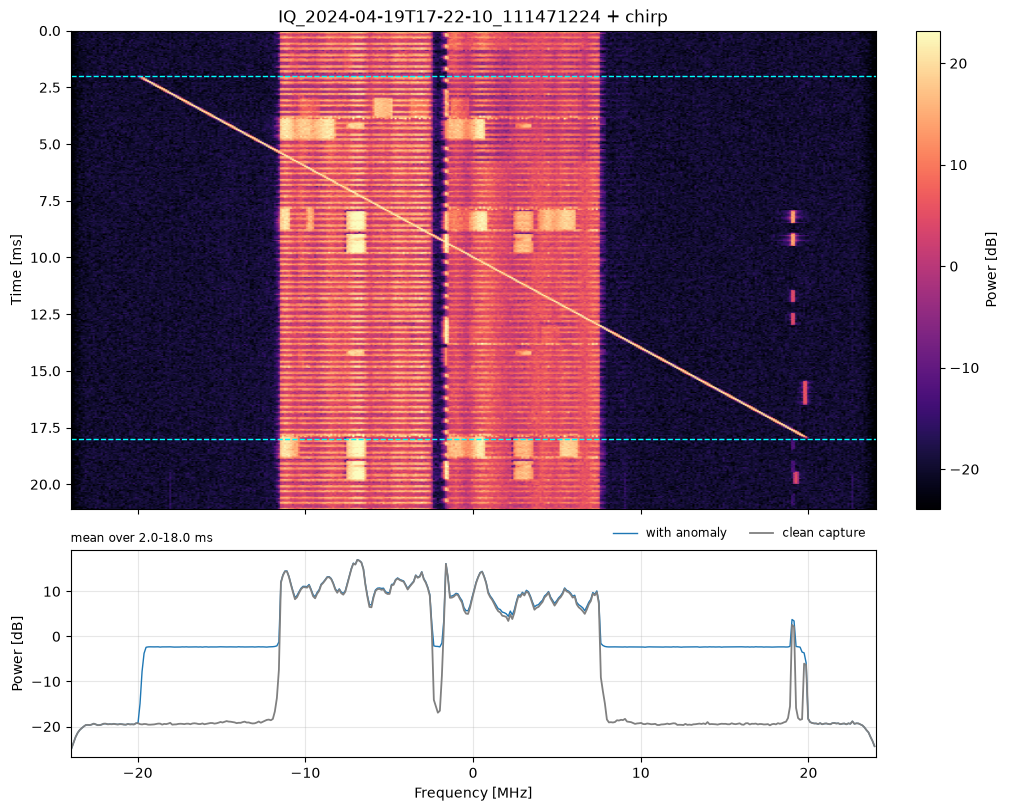

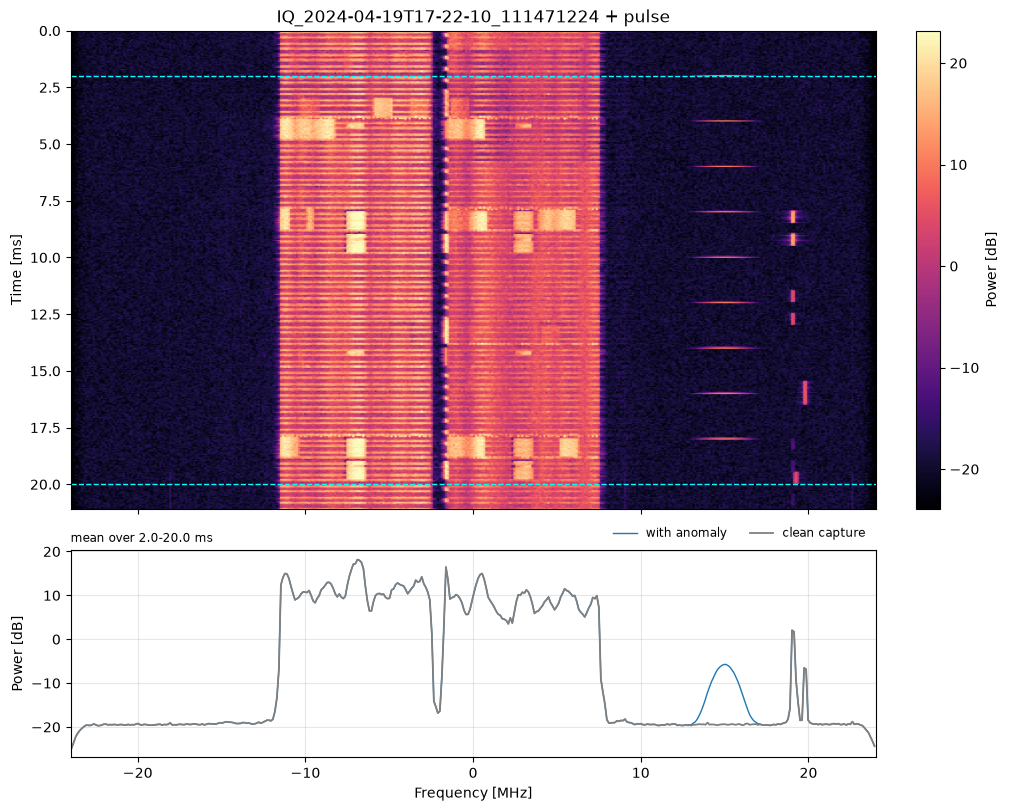

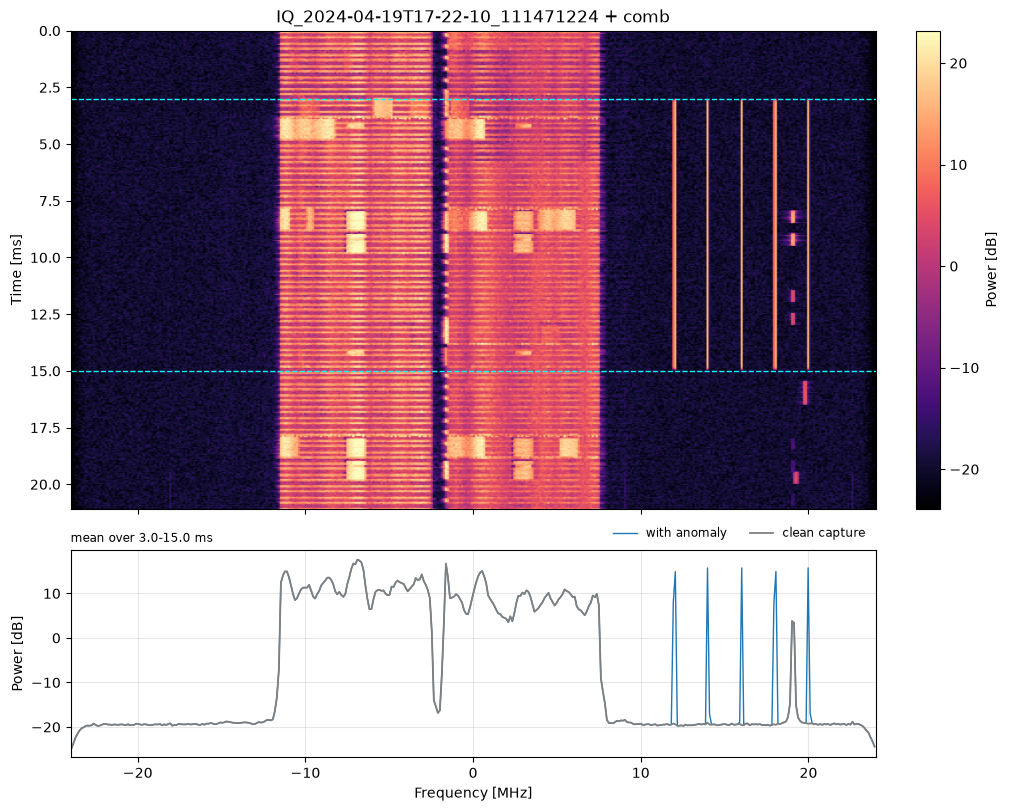

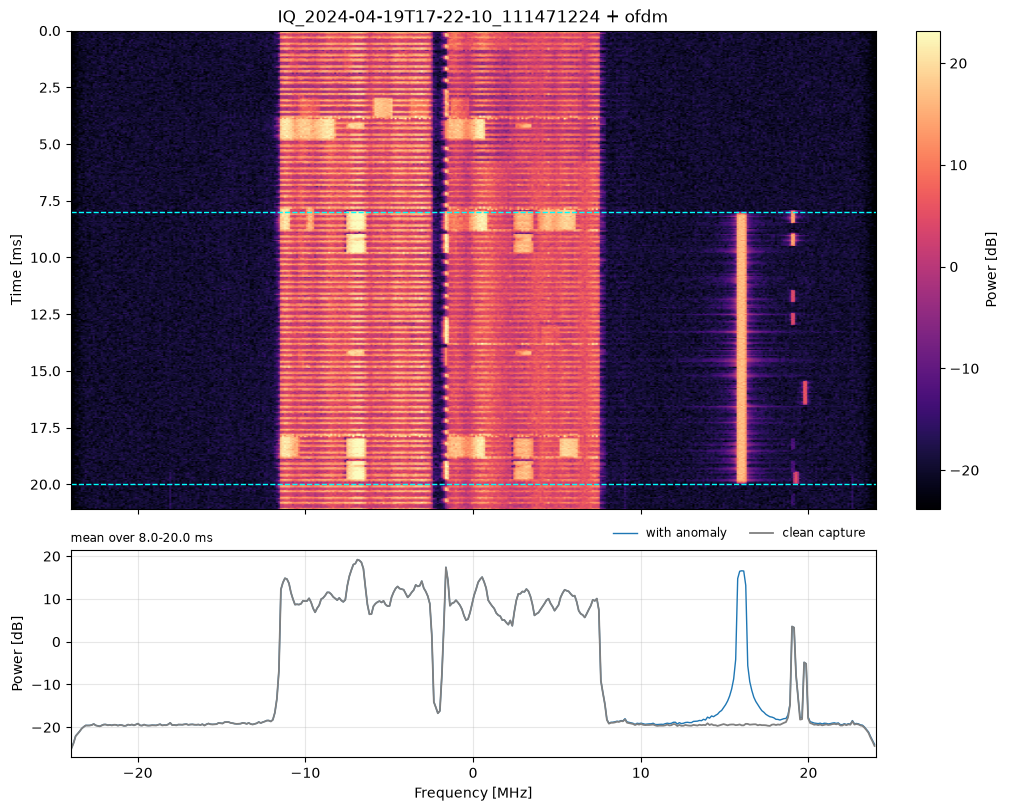

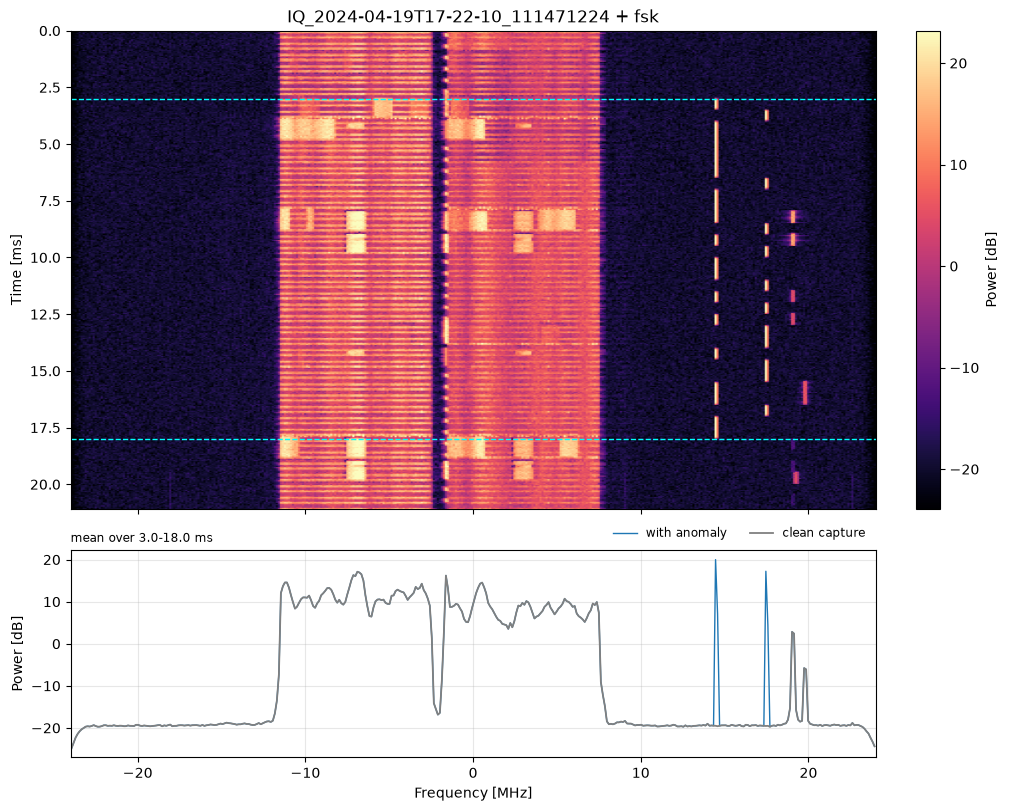

In [5]:
rng = np.random.default_rng(0)

# Anomaly type -> (function, its parameters)
examples = {
    "tone": (add_tone, dict(freq=15e6, start=5e-3, stop=10e-3, isr=-10, ramp=10e-10)),
    "chirp": (add_chirp, dict(f_start=-20e6, f_stop=20e6, start=2e-3, stop=18e-3, isr=-10)),
    "pulse": (add_pulse, dict(freq=15e6, start=2e-3, stop=20e-3, isr=10)),
    "comb": (add_comb, dict(f_first=12e6, spacing=2e6, n_tones=5, start=3e-3, stop=15e-3,
                            isr=-10)),
    "ofdm": (add_ofdm, dict(freq=16e6, bandwidth=5e5, start=8e-3, stop=20e-3, isr=-10,
                            rng=rng)),
    "fsk": (add_fsk, dict(freq=16e6, deviation=1.5e6, symbol_duration=0.5e-3,
                          start=3e-3, stop=18e-3, isr=-10, rng=rng)),
}

for kind, (add_anomaly, params) in examples.items():
    sxx_db, _ = iq_to_spectrogram(add_anomaly(iq, fs, **params), fs)
    show(sxx_db, name + " + " + kind, params["start"], params["stop"], reference=clean_db)

## Random scene from the pipeline

Several anomalies with different time windows, so the spectrum averages the whole capture.

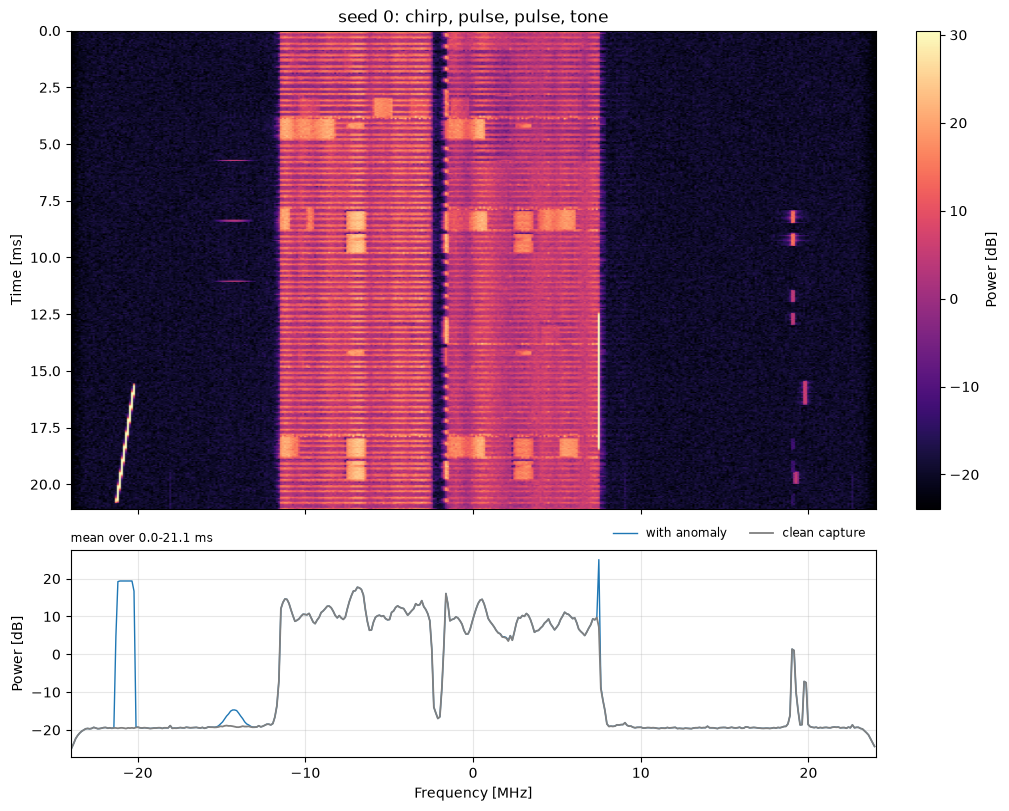

In [6]:
from pipeline import load_config, generate_spectrogram

cfg = load_config("configs/v1.toml")
sample = generate_spectrogram(path + ".bin", cfg, np.random.default_rng(0))

# The pipeline crops the capture to fewer samples, but the spectrogram never reaches the
# cropped part, so clean_db is the right reference
show(sample["image_db"], "seed 0: " + ", ".join(a["type"] for a in sample["anomalies"]),
     reference=clean_db)